In [32]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
RAW_FILE = ROOT / "data" / "raw" / "hotels.csv"

df = pd.read_csv(RAW_FILE, low_memory=False)
df.columns = df.columns.str.strip()

print("Ukuran dataset:", df.shape)

month_map = {
    month: number
    for number, month in enumerate(
        [
            "January", "February", "March", "April",
            "May", "June", "July", "August",
            "September", "October", "November", "December",
        ],
        start=1,
    )
}

df["arrival_month"] = (
    df["arrival_date_month"].str.strip().map(month_map)
)

df["arrival_date"] = pd.to_datetime({
    "year": df["arrival_date_year"],
    "month": df["arrival_month"],
    "day": df["arrival_date_day_of_month"],
}, errors="coerce")
display(
    df[
        [
            "arrival_date_year",
            "arrival_date_month",
            "arrival_date_day_of_month",
            "arrival_date",
        ]
    ].head(10)
)


Ukuran dataset: (119390, 32)


,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2015,July,1,2015-07-01
1,2015,July,1,2015-07-01
2,2015,July,1,2015-07-01
3,2015,July,1,2015-07-01
4,2015,July,1,2015-07-01
5,2015,July,1,2015-07-01
6,2015,July,1,2015-07-01
7,2015,July,1,2015-07-01
8,2015,July,1,2015-07-01
9,2015,July,1,2015-07-01


In [33]:
print("Distribusi status pembatalan:")
display(df["is_canceled"].value_counts())

print("Contoh reservasi beserta statusnya:")
display(
    df[
        ["hotel", "is_canceled", "arrival_date"]
    ].head(10)
)

Distribusi status pembatalan:


is_canceled
0    75166
1    44224
Name: count, dtype: int64

Contoh reservasi beserta statusnya:


,hotel,is_canceled,arrival_date
0,Resort Hotel,0,2015-07-01
1,Resort Hotel,0,2015-07-01
2,Resort Hotel,0,2015-07-01
3,Resort Hotel,0,2015-07-01
4,Resort Hotel,0,2015-07-01
5,Resort Hotel,0,2015-07-01
6,Resort Hotel,0,2015-07-01
7,Resort Hotel,0,2015-07-01
8,Resort Hotel,1,2015-07-01
9,Resort Hotel,1,2015-07-01


In [34]:
# Pilih reservasi yang tidak dibatalkan
df_not_canceled = df[df["is_canceled"] == 0]

print("Jumlah seluruh reservasi:", len(df))
print("Jumlah reservasi tidak dibatalkan:", len(df_not_canceled))

display(
    df_not_canceled[
        ["hotel", "is_canceled", "arrival_date"]
    ].head(10)
)

Jumlah seluruh reservasi: 119390
Jumlah reservasi tidak dibatalkan: 75166


,hotel,is_canceled,arrival_date
0,Resort Hotel,0,2015-07-01
1,Resort Hotel,0,2015-07-01
2,Resort Hotel,0,2015-07-01
3,Resort Hotel,0,2015-07-01
4,Resort Hotel,0,2015-07-01
5,Resort Hotel,0,2015-07-01
6,Resort Hotel,0,2015-07-01
7,Resort Hotel,0,2015-07-01
11,Resort Hotel,0,2015-07-01
12,Resort Hotel,0,2015-07-01


In [35]:
# Pilih reservasi City Hotel yang tidak dibatalkan
city_hotel = df_not_canceled[
    df_not_canceled["hotel"] == "City Hotel"
]

print("Reservasi tidak dibatalkan:", len(df_not_canceled))
print("Reservasi City Hotel:", len(city_hotel))

display(
    city_hotel[
        ["hotel", "is_canceled", "arrival_date"]
    ].head(10)
)

Reservasi tidak dibatalkan: 75166
Reservasi City Hotel: 0


,hotel,is_canceled,arrival_date


In [47]:
print("Daftar jenis hotel:")
display(df["hotel"].value_counts(dropna=False))

print("\nRepresentasi teks nama hotel:")
display(df["hotel"].drop_duplicates().map(repr))

Daftar jenis hotel:


hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64


Representasi teks nama hotel:


0        'Resort Hotel'
40060      'City Hotel'
Name: hotel, dtype: object

In [46]:
# Hapus spasi di awal dan akhir nama hotel
df["hotel"] = df["hotel"].str.strip()

# Periksa hasilnya
display(df["hotel"].value_counts())

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

In [45]:
print("Jumlah df:", len(df))
print("Jumlah df_not_canceled:", len(df_not_canceled))
print("Jumlah city_hotel:", len(city_hotel))

print("\nJenis hotel di df:")
display(df["hotel"].value_counts(dropna=False))

print("\nJenis hotel di df_not_canceled:")
display(df_not_canceled["hotel"].value_counts(dropna=False))

print("\nContoh isi city_hotel:")
display(city_hotel.head())

Jumlah df: 119390
Jumlah df_not_canceled: 75166
Jumlah city_hotel: 0

Jenis hotel di df:


hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64


Jenis hotel di df_not_canceled:


hotel
City Hotel      46228
Resort Hotel    28938
Name: count, dtype: int64


Contoh isi city_hotel:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_month,arrival_date


In [58]:
# Pastikan nama hotel bersih
df_not_canceled["hotel"] = (
    df_not_canceled["hotel"].str.strip()
)

# Buat ulang filter City Hotel
city_hotel = df_not_canceled.loc[
    df_not_canceled["hotel"] == "City Hotel"
].copy()

print("Jumlah City Hotel:", len(city_hotel))

# Hitung reservasi per tanggal
daily_reservations = (
    city_hotel.groupby("arrival_date")
    .size()
    .sort_index()
    .rename("jumlah_reservasi")
)

print("Jumlah tanggal tercatat:", len(daily_reservations))
display(daily_reservations.head(10))

Jumlah City Hotel: 46228
Jumlah tanggal tercatat: 788


arrival_date
2015-07-01    65
2015-07-02     1
2015-07-03    10
2015-07-04     9
2015-07-06     1
2015-07-07     2
2015-07-08    24
2015-07-09     1
2015-07-10     2
2015-07-11    31
Name: jumlah_reservasi, dtype: int64

In [59]:
# Pisahkan 30 hari terakhir sebagai data uji
test_days = 30

train = daily_reservations.iloc[:-test_days]
test = daily_reservations.iloc[-test_days:]

print("Data latih:", len(train), "hari")
print("Data uji:", len(test), "hari")
print("Periode pengujian:", test.index.min().date(),
      "sampai", test.index.max().date())

Data latih: 758 hari
Data uji: 30 hari
Periode pengujian: 2017-08-02 sampai 2017-08-31


In [60]:
from sklearn.metrics import mean_absolute_error

# Gunakan nilai hari terakhir data latih sebagai prediksi
last_value = train.iloc[-1]

pred_naive = pd.Series(
    last_value,
    index=test.index,
    name="prediksi"
)

# Bandingkan prediksi dengan nilai aktual
comparison = pd.DataFrame({
    "aktual": test,
    "prediksi": pred_naive
})

display(comparison.head(10))

,aktual,prediksi
arrival_date,,
2017-08-02,73,55
2017-08-03,79,55
2017-08-04,69,55
2017-08-05,51,55
2017-08-06,48,55
2017-08-07,81,55
2017-08-08,47,55
2017-08-09,71,55
2017-08-10,60,55


In [61]:
mae_naive = mean_absolute_error(
    comparison["aktual"],
    comparison["prediksi"]
)

print("Nilai terakhir data latih:", last_value)
print("MAE Naive Forecasting:", round(mae_naive, 2))

Nilai terakhir data latih: 55
MAE Naive Forecasting: 14.83


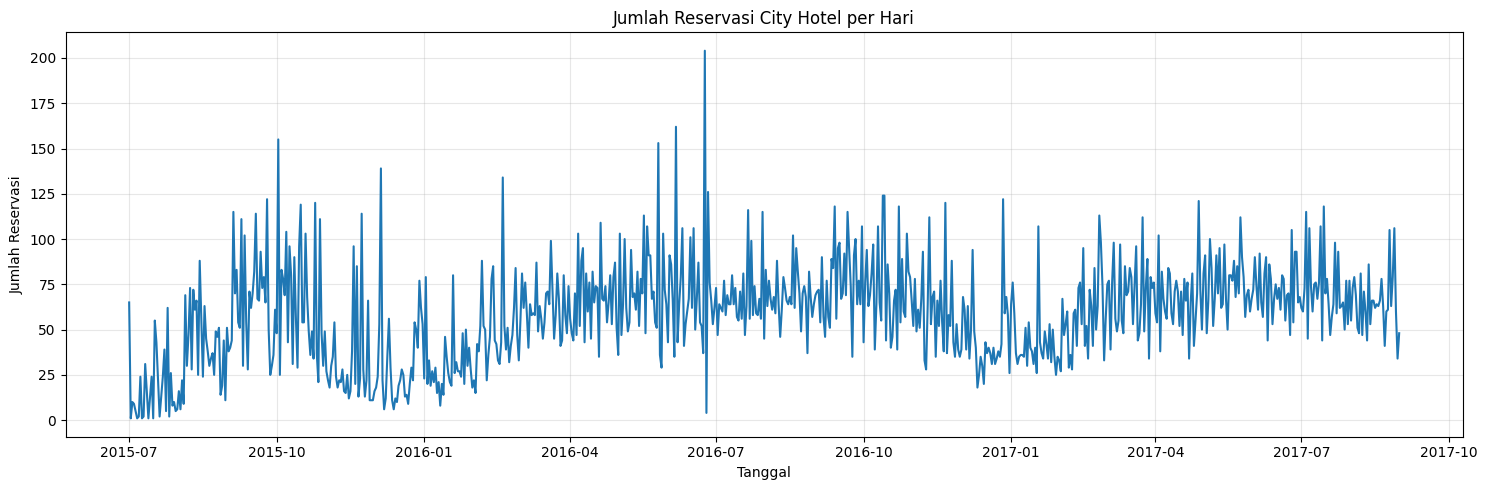

In [62]:
plt.figure(figsize=(15, 5))

plt.plot(
    daily_reservations.index,
    daily_reservations.values
)

plt.title("Jumlah Reservasi City Hotel per Hari")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Reservasi")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [63]:
# 30 hari terakhir untuk menguji prediksi
test_days = 30

train = daily_reservations.iloc[:-test_days]
test = daily_reservations.iloc[-test_days:]

print("Data latih:", len(train), "hari")
print("Data uji:", len(test), "hari")
print("Periode uji:", test.index.min().date(),
      "sampai", test.index.max().date())

Data latih: 758 hari
Data uji: 30 hari
Periode uji: 2017-08-02 sampai 2017-08-31


In [64]:
import pandas as pd
from sklearn.metrics import mean_absolute_error

# Prediksi memakai nilai pada hari terakhir data latih
last_value = train.iloc[-1]

pred_naive = pd.Series(
    last_value,
    index=test.index,
    name="prediksi"
)

comparison = pd.DataFrame({
    "aktual": test,
    "prediksi": pred_naive
})

display(comparison.head(10))

,aktual,prediksi
arrival_date,,
2017-08-02,73,55
2017-08-03,79,55
2017-08-04,69,55
2017-08-05,51,55
2017-08-06,48,55
2017-08-07,81,55
2017-08-08,47,55
2017-08-09,71,55
2017-08-10,60,55


In [65]:
mae_naive = mean_absolute_error(
    comparison["aktual"],
    comparison["prediksi"]
)

print("Nilai terakhir data latih:", last_value)
print("MAE Naive Forecasting:", round(mae_naive, 2))

Nilai terakhir data latih: 55
MAE Naive Forecasting: 14.83
